# Kunci Lab 0: Mulai dari Nol

Jawaban latihan Lab 0.



## Persiapan: alamat data



**Alur sesi:** kenali arti kolom, baca data Indonesia dari beberapa format,
bandingkan hasil tabelnya, lalu buat grafik. Setelah itu, lanjutkan contoh
regresi pertama. Jalankan sel berurutan; semua pembacaan data sudah disiapkan.

In [1]:
URL_DATA = "https://raw.githubusercontent.com/akhiyarwaladi/ekonometrika_coding_workshop/main/data/"

print("Alamat data siap. Jalankan sel pembacaan CSV berikutnya.")


Alamat data siap. Jalankan sel pembacaan CSV berikutnya.


In [2]:
%pip install -q "openpyxl==3.1.5" "pyreadstat==1.3.2" "pyarrow==19.0.0"

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
from sklearn.linear_model import LinearRegression
import statsmodels.api as sm



import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "axes.labelsize": 11, "axes.titleweight": "bold", "legend.fontsize": 10})


## Praktik format data: jawaban

Pakai tabel makro Indonesia yang diperkenalkan pada Sesi 0. CSV sumber dan
salinan Excel, SPSS, serta Stata memuat angka yang sama: 26 tahun, dari 2000
sampai 2025. Definisi setiap kolom tersedia sebelum pembacaan CSV.
Contoh lengkap tujuh format tersedia pada notebook contoh Sesi 0.

Jalankan sel secara berurutan. Tidak perlu membuka Excel, SPSS, atau Stata.

<!-- kamus_variabel:idn_makro_tahunan.csv -->

### Kenali data: Makroekonomi Indonesia tahunan

**Data:** `data/idn_makro_tahunan.csv`. **Satu baris:** satu tahun kalender untuk Indonesia.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `negara` | Kode negara; IDN menunjukkan Indonesia. | Kode ISO negara | Penanda, bukan besaran ekonomi |
| `tahun` | Tahun kalender pengamatan. | Tahun | Penanda waktu |
| `PDB_Growth` | Laju pertumbuhan tahunan PDB riil (Produk Domestik Bruto). | Persen per tahun; NY.GDP.MKTP.KD.ZG | Target pertumbuhan pada model panel |
| `Inflasi` | Kenaikan tahunan indeks harga konsumen. | Persen per tahun; FP.CPI.TOTL.ZG | Y atau X sesuai model |
| `Pengangguran` | Pengangguran sebagai bagian dari total angkatan kerja, estimasi model ILO. | Persen angkatan kerja; SL.UEM.TOTL.ZS | X: penjelas |
| `Kurs_USD` | Kurs resmi rata-rata periode: mata uang lokal untuk memperoleh satu dolar AS. | Mata uang lokal per US$1; PA.NUS.FCRF | X: penjelas |
| `Angkatan_Kerja` | Penduduk yang bekerja atau aktif mencari pekerjaan. | Orang; SL.TLF.TOTL.IN | X: penjelas |

Kurs_USD untuk Indonesia bersatuan rupiah per US$1. Inflasi dan pertumbuhan adalah laju persen, bukan nilai level harga atau level PDB.

Sumber definisi: [rujukan data](https://databank.worldbank.org/source/world-development-indicators).


In [4]:
URL_FORMAT = URL_DATA + "contoh_format/"
makro_csv = pd.read_csv(URL_DATA + "idn_makro_tahunan.csv")
makro_csv.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


`sheet_name="data"` memilih lembar data pada Excel. SPSS dibaca dari
salinan `.sav` yang diunduh otomatis ke runtime notebook.

In [5]:
makro_excel = pd.read_excel(URL_FORMAT + "idn_makro_tahunan.xlsx", sheet_name="data")
makro_excel.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


In [6]:
from urllib.request import urlretrieve

urlretrieve(URL_FORMAT + "idn_makro_tahunan.sav", "idn_makro_tahunan.sav")
makro_spss = pd.read_spss("idn_makro_tahunan.sav")
makro_spss.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000.0,4.920068,3.688620,6.077,8421.775000,101308307.0
1,IDN,2001.0,3.643466,11.500116,6.082,10260.850000,102354432.0
2,IDN,2002.0,4.499475,11.900120,6.604,9311.191667,102498864.0
3,IDN,2003.0,4.780369,6.757313,6.657,8577.133333,103909546.0
4,IDN,2004.0,5.030874,6.064062,7.303,8938.850000,105759801.0


In [7]:
makro_stata = pd.read_stata(URL_FORMAT + "idn_makro_tahunan.dta")
makro_stata.head()

,negara,tahun,PDB_Growth,Inflasi,Pengangguran,Kurs_USD,Angkatan_Kerja
0,IDN,2000,4.920068,3.688620,6.077,8421.775000,101308307
1,IDN,2001,3.643466,11.500116,6.082,10260.850000,102354432
2,IDN,2002,4.499475,11.900120,6.604,9311.191667,102498864
3,IDN,2003,4.780369,6.757313,6.657,8577.133333,103909546
4,IDN,2004,5.030874,6.064062,7.303,8938.850000,105759801


**Coba sendiri:** bandingkan `makro_csv.shape` dan `makro_spss.shape`.
Berapa jumlah baris serta kolomnya? Hitung rata-rata `Inflasi` dari tabel
Excel dan SPSS dengan `.mean()`. Apakah hasilnya sama?

In [8]:
print("CSV :", makro_csv.shape)
print("SPSS:", makro_spss.shape)
print("Rata-rata inflasi Excel:", round(makro_excel["Inflasi"].mean(), 3))
print("Rata-rata inflasi SPSS :", round(makro_spss["Inflasi"].mean(), 3))

CSV : (26, 7)
SPSS: (26, 7)
Rata-rata inflasi Excel: 5.671
Rata-rata inflasi SPSS : 5.671


Keduanya berisi 26 baris dan tujuh kolom. Rata-rata inflasi yang sama
menunjukkan bahwa perbedaan format tidak mengubah angka pada salinan latihan ini.

### Dari tabel SPSS menjadi grafik

Setelah dibaca, hasilnya adalah tabel pandas atau **DataFrame**. Perintah grafiknya
sama seperti untuk CSV atau Excel. Kita memakai kolom `tahun` dan `Inflasi`.

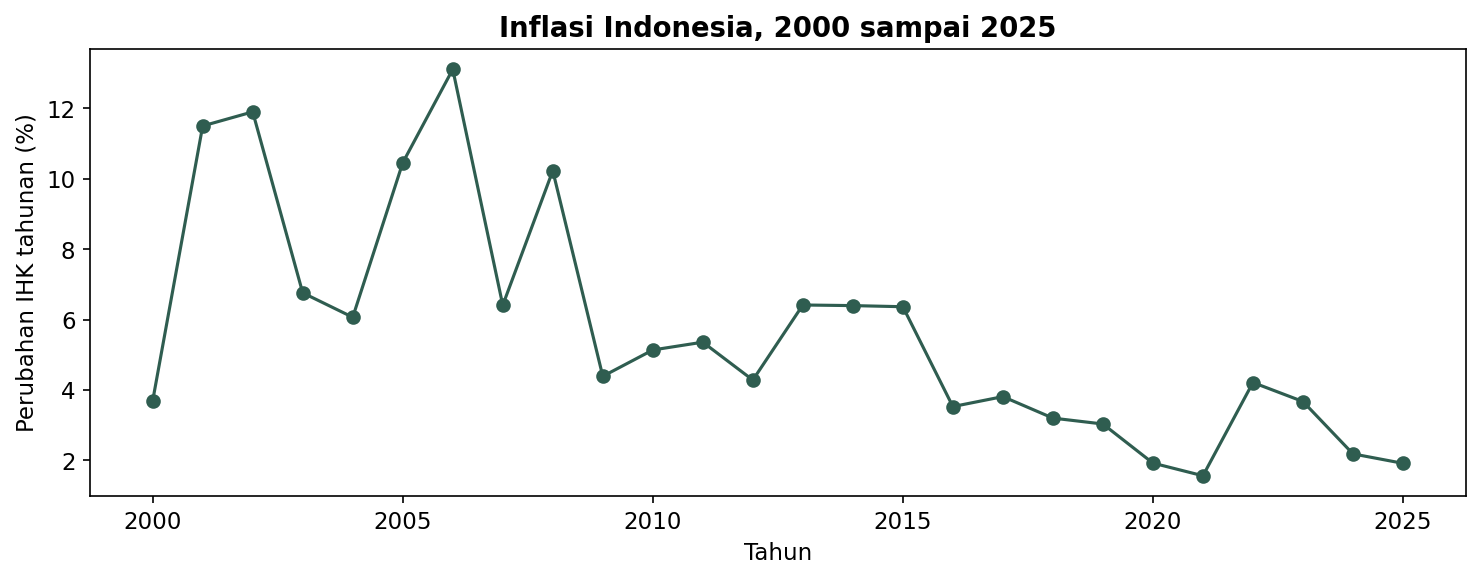

In [9]:
makro_spss.plot(x="tahun", y="Inflasi", marker="o", color="#2F5D50",
                figsize=(10, 4), legend=False)
plt.title("Inflasi Indonesia, 2000 sampai 2025")
plt.xlabel("Tahun")
plt.ylabel("Perubahan IHK tahunan (%)")
plt.xticks([2000, 2005, 2010, 2015, 2020, 2025])
plt.tight_layout()
plt.show()

**Cara membaca:** satu titik menunjukkan inflasi Indonesia pada satu tahun.
Sumbu mendatar menunjukkan tahun; sumbu tegak menunjukkan perubahan tahunan
Indeks Harga Konsumen (IHK) dalam persen. Misalnya, nilai 5 berarti IHK naik
sekitar 5 persen dari tahun sebelumnya. Garis membantu melihat perubahan antarwaktu.
Grafik ini berasal dari berkas SPSS, tetapi isinya sama dengan tabel CSV sumber.
Ukuran inflasi tahunan World Bank ini jangan disamakan begitu saja dengan inflasi
bulanan atau angka Desember terhadap Desember.

Berkas sudah menjadi tabel pandas yang dapat diperiksa dan digambar.
Sekarang lanjutkan contoh regresi di bawah dengan data latihan yang telah disiapkan.

## Latihan 1 dan 2: baca data dan hitung rata-rata



<!-- kamus_variabel:uts_4.csv -->

### Kenali data: Angka harapan hidup

**Data:** `data/uts_4.csv`. **Satu baris:** satu negara pada contoh latihan.

| Variabel/kolom | Pengertian | Satuan atau kode | Peran |
|---|---|---|---|
| `Y_Angka_Harapan_Hidup` | Rata-rata lama hidup yang diharapkan menurut indikator pada contoh. | Tahun | Y: target |
| `X1_Pengeluaran_Kesehatan` | Pengeluaran kesehatan per penduduk (per kapita). | Uang per kapita; mata uang/periode tidak dirinci | X: penjelas |
| `X2_Tingkat_Imunisasi` | Persentase anak yang memperoleh imunisasi. | Persen; jenis imunisasi tidak dirinci | X: penjelas |
| `X3_Konsumsi_Kalori` | Rata-rata konsumsi energi makanan per hari. | Kalori harian; rincian satuan energi mengikuti sumber | X: penjelas |

Sumber definisi: [rujukan data](https://paggalih.github.io/matkul/sem2025-01/ekonometrika/).


In [10]:
harapan_hidup = pd.read_csv(URL_DATA + "uts_4.csv")
print("Jumlah observasi:", len(harapan_hidup))
harapan_hidup.head()


Jumlah observasi: 50


,Y_Angka_Harapan_Hidup,X1_Pengeluaran_Kesehatan,X2_Tingkat_Imunisasi,X3_Konsumsi_Kalori
0,75.5,1550,92,2850
1,72.1,850,85,2600
2,81.2,4500,98,3300
3,82.5,5500,99,3450
4,68.5,350,75,2300


In [11]:
print(
    "Rata-rata harapan hidup :", round(harapan_hidup["Y_Angka_Harapan_Hidup"].mean(), 2)
)
print(
    "Rata-rata imunisasi     :", round(harapan_hidup["X2_Tingkat_Imunisasi"].mean(), 2)
)


Rata-rata harapan hidup : 76.95
Rata-rata imunisasi     : 91.86


## Latihan 3: regresi sederhana



In [12]:
sampel_model = harapan_hidup[
    ["Y_Angka_Harapan_Hidup", "X1_Pengeluaran_Kesehatan"]
].dropna()
X_model = sampel_model[["X1_Pengeluaran_Kesehatan"]]
y_model = sampel_model["Y_Angka_Harapan_Hidup"]

model = LinearRegression()
model.fit(X_model, y_model)

koefisien_model = pd.Series(model.coef_, index=X_model.columns)
koefisien_model.loc["Intercept"] = model.intercept_


### Lihat hasil model: Harapan hidup (tahun)

Di kiri, bandingkan nilai aktual dan prediksi. Di kanan, lihat residual, yaitu aktual dikurangi prediksi. Kedua panel memakai data latihan yang sama dengan model.

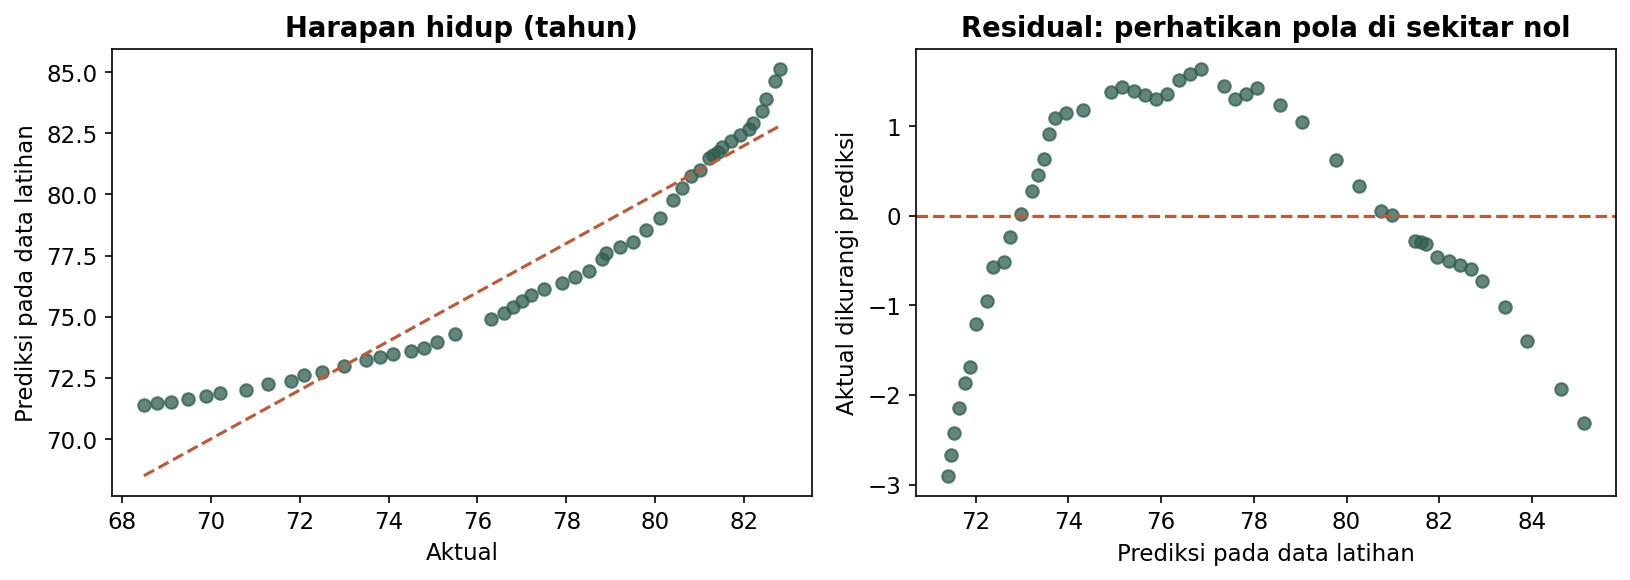

In [13]:
prediksi_visual = model.predict(X_model)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_model, prediksi_visual, color="#2F5D50", alpha=0.75)
batas_visual = [y_model.min(), y_model.max()]
axes[0].plot(batas_visual, batas_visual, "--", color="#C15937")
axes[0].set(xlabel="Aktual", ylabel="Prediksi pada data latihan", title="Harapan hidup (tahun)")
axes[1].scatter(prediksi_visual, y_model - prediksi_visual, color="#2F5D50", alpha=0.75)
axes[1].axhline(0, color="#C15937", linestyle="--")
axes[1].set(xlabel="Prediksi pada data latihan", ylabel="Aktual dikurangi prediksi", title="Residual: perhatikan pola di sekitar nol")
plt.tight_layout()
plt.show()

**Cara membaca:** titik dekat diagonal mempunyai prediksi yang dekat aktual. Pada panel residual, cari pola melengkung atau lebar sebaran yang berubah. Kecocokan pada data latihan belum mengukur kemampuan memprediksi data baru. Sesudah membaca gambar, hubungkan pola itu dengan angka model dan pertanyaan latihannya. Lengkungan residual mengingatkan bahwa contoh regresi awal ini belum menyelesaikan seluruh persoalan spesifikasi; pertanyaan tentang bentuk model dilanjutkan pada Sesi 2.

**Pelengkap statistik.** Model dan prediksinya sudah tersedia. Tabel berikut menambahkan standard error dan p-value pada sampel yang sama; gunakan penjelasan setelah tabel untuk memilih angka yang dibaca.

In [14]:
# Pelengkap statistik: standard error dan pengujian pada sampel yang sama.
uji_model = sm.OLS(
    y_model,
    sm.add_constant(X_model, has_constant="add").rename(columns={"const": "Intercept"}),
).fit()
print(koefisien_model.round(5))
print(uji_model.pvalues.round(4))


X1_Pengeluaran_Kesehatan     0.00243
Intercept                   70.55237
dtype: float64
Intercept                   0.0
X1_Pengeluaran_Kesehatan    0.0
dtype: float64


Kesimpulan: koefisien pengeluaran kesehatan 0,00243 dengan p-value
0,0000, jadi signifikan. Setiap tambahan satu unit pengeluaran kesehatan
diiringi kenaikan harapan hidup 0,00243 tahun. R kuadrat model ini
sekitar 0,91.
